# Step 06: Inference

Tests for `06-inference/inference.py`. Write code in the `.py` file, only import and test here.

Two ideas: **sampling** (how to pick the next token) and the **KV cache** (stop recomputing old work).

Needs the checkpoint from step 05 (`uv run python 05-training/train.py`) for sections 5 onward.

Run the cells top to bottom (Run All).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import time
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.append("06-inference")
from inference import (
    top_k_filter, top_p_filter, sample_next,
    generate, generate_cached, new_cache, forward_cached,
    load_model, complete,
)
import tiktoken

enc = tiktoken.get_encoding("gpt2")

## 1. Temperature

The model outputs a raw score (logit) per token. Dividing the scores by a temperature before softmax reshapes the probabilities:
- below 1: sharper, the favourite wins more often (safe, repetitive)
- above 1: flatter, unlikely tokens get a chance (creative, error-prone)
- 0: greedy, always the single best token

A toy vocabulary of 5 tokens makes this visible.

In [2]:
logits = torch.tensor([[4.0, 3.0, 2.0, 1.0, 0.0]])     # (B=1, V=5)

for T in [0.5, 1.0, 2.0]:
    print(f"T={T}:", F.softmax(logits / T, dim=-1)[0].round(decimals=3))
# T=0.5: [0.865 0.117 0.016 0.002 0.   ]   sharper
# T=1.0: [0.636 0.234 0.086 0.032 0.012]
# T=2.0: [0.429 0.26  0.158 0.096 0.058]   flatter

print("greedy picks token", sample_next(logits, temperature=0).item())   # expect 0

T=0.5: tensor([0.8650, 0.1170, 0.0160, 0.0020, 0.0000])
T=1.0: tensor([0.6360, 0.2340, 0.0860, 0.0320, 0.0120])
T=2.0: tensor([0.4290, 0.2600, 0.1580, 0.0960, 0.0580])
greedy picks token 0


## 2. Top-k

Keep only the k most likely tokens, set the rest to probability 0, renormalize. Cuts off the long tail of nonsense tokens (a vocabulary has 50,000 of them).

In [3]:
print(F.softmax(top_k_filter(logits, 2), dim=-1)[0].round(decimals=3))
# expect [0.731 0.269 0.    0.    0.   ]: only the top 2 survive

tensor([0.7310, 0.2690, 0.0000, 0.0000, 0.0000])


## 3. Top-p (nucleus)

Keep the smallest set of top tokens whose probabilities add up to at least p. Unlike top-k, the number of survivors adapts: few when the model is confident, many when it is unsure.

In [4]:
print(F.softmax(top_p_filter(logits, 0.9), dim=-1)[0].round(decimals=3))   # expect 3 survive: 0.636+0.234+0.086 covers 0.9
print(F.softmax(top_p_filter(logits, 0.5), dim=-1)[0].round(decimals=3))   # expect only the top token: it alone covers 0.5

tensor([0.6650, 0.2450, 0.0900, 0.0000, 0.0000])
tensor([1., 0., 0., 0., 0.])


## 4. Does sampling match the probabilities?

Draw 5000 samples with `top_k=3` and count them. Tokens 3 and 4 must never appear, and the other three should appear in proportion to their probabilities.

In [5]:
torch.manual_seed(0)
samples = sample_next(logits.expand(5000, -1), top_k=3).flatten()
counts = torch.bincount(samples, minlength=5)
print(counts.tolist())              # expect about [3380, 1184, 436, 0, 0]
print((counts / 5000).round(decimals=3).tolist())   # expect about [0.676, 0.237, 0.087, 0, 0]  (0.636/0.94, 0.234/0.94, 0.086/0.94)

[3380, 1184, 436, 0, 0]
[0.6759999990463257, 0.2370000034570694, 0.08699999749660492, 0.0, 0.0]


## 5. Load the model trained in step 05

The checkpoint stores the weights and the config, so the model can be rebuilt without remembering the hyperparameters.

In [6]:
model, ckpt = load_model()
device = next(model.parameters()).device

print(f"parameters: {model.num_params():,}")
print(f"trained for {ckpt['step'] + 1} steps, lowest val loss seen in training {ckpt['best_val']:.3f}")
print(ckpt["config"])

parameters: 30,037,632
trained for 4000 steps, lowest val loss seen in training 2.100
{'vocab_size': 50257, 'n_embd': 384, 'n_heads': 6, 'n_layers': 6, 'block_size': 256, 'tie_weights': True}


## 6. Same prompt, different sampling

Same model, same prompt, only the sampling changes. Read the three outputs side by side.

In [7]:
prompt = "Once upon a time"

torch.manual_seed(0)
for name, cfg in [("greedy", dict(temperature=0)),
                  ("temperature 0.8, top-k 40", dict(temperature=0.8, top_k=40)),
                  ("temperature 1.5 (too hot)", dict(temperature=1.5))]:
    print(f"--- {name} ---")
    print(complete(model, prompt, 120, **cfg), "\n")

--- greedy ---
Once upon a time, there was a little girl named Lily. She loved to play outside and explore the world around her. One day, she found a big, shiny rock in the ground. She was so happy and wanted to touch it.
Lily's mommy said, "Lily, you can't touch the rock. It's not safe to touch it." Lily nodded her head and said, "I love you, Mommy."
Later that day, Lily's mommy asked her to help clean up the rock. Lily was happy and said, "Thank you, Mommy! I love 

--- temperature 0.8, top-k 40 ---
Once upon a time, there was a little girl named Lily. She loved to read the book with her mommy and daddy. They would read for a while, but they didn't remember.
One day, Lily's mommy asked her to help with the book. Lily was scared, but her mommy reminded her to follow the rules. She gave her the book back to the shelf and she read it carefully.
When they finished, Lily's mommy asked her to let her read the book. Lily replied, "Okay mommy! I'm so excited!" Her mommy smiled and said, " 



## 7. KV cache: same answer

First check that the cache changes nothing about the output, only the cost. Process a sequence in one go, then again as prefill + one token at a time with the cache, and compare logits.

In [8]:
ids = torch.tensor([enc.encode_ordinary("One day, a little girl named Lily found a shiny stone.")], device=device)

with torch.no_grad():
    full, _ = model(ids)                       # (1, T, V) all at once
    cache = new_cache(model)
    parts = [forward_cached(model, ids[:, :5], cache)]   # prefill 5 tokens
    for t in range(5, ids.shape[1]):
        parts.append(forward_cached(model, ids[:, t:t+1], cache))   # then one at a time
    incremental = torch.cat(parts, dim=1)

print(full.shape, incremental.shape)           # same shapes
print("max difference:", (full - incremental).abs().max().item())   # expect ~1e-4 or smaller (float rounding)

torch.manual_seed(0)
start = torch.tensor([enc.encode_ordinary("Once upon a time")], device=device)
a = generate(model, start, 60, temperature=0)
b = generate_cached(model, start, 60, temperature=0)
print("greedy outputs identical:", torch.equal(a, b))   # expect True

torch.Size([1, 13, 50257]) torch.Size([1, 13, 50257])
max difference: 2.002716064453125e-05
greedy outputs identical: True


## 8. KV cache: speed

Without the cache every new token re-runs the whole sequence, so total work grows like n squared. With it, each step handles one token. On this small model the GPU gain is modest: its speed is limited by the per-operation overhead of many tiny kernels, not by arithmetic (notice the no-cache speed stays flat as the sequence grows). The CPU test below is limited by arithmetic, where the saving shows up clearly.

  25 new tokens: no cache  0.15s (172.3 tok/s) | cache  0.12s (205.5 tok/s) | 1.2x
  50 new tokens: no cache  0.29s (175.4 tok/s) | cache  0.24s (210.8 tok/s) | 1.2x
 100 new tokens: no cache  0.58s (173.5 tok/s) | cache  0.48s (208.3 tok/s) | 1.2x
 200 new tokens: no cache  1.13s (177.0 tok/s) | cache  0.96s (209.3 tok/s) | 1.2x


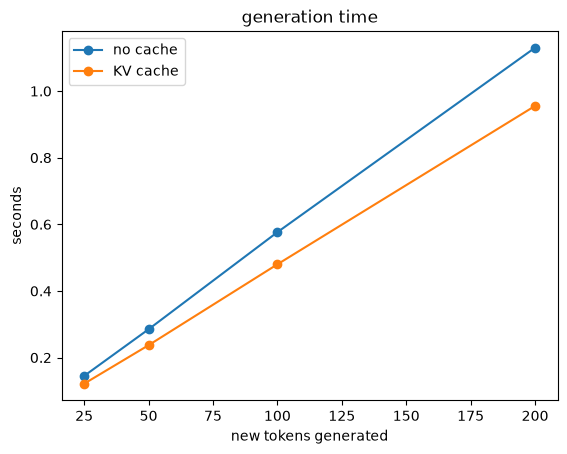

In [9]:
# warm up first: the first calls on a GPU pay one-time setup costs that would distort the timing
for fn in (generate, generate_cached):
    fn(model, start, 200, temperature=0)

def timed(fn, n_new):
    best = float("inf")
    for _ in range(2):                 # best of 2 runs
        if device == "mps":
            torch.mps.synchronize()    # GPU work is asynchronous: wait for it before reading the clock
        t0 = time.time()
        fn(model, start, n_new, temperature=0)
        if device == "mps":
            torch.mps.synchronize()
        best = min(best, time.time() - t0)
    return best

lengths = [25, 50, 100, 200]
plain = [timed(generate, n) for n in lengths]
cached = [timed(generate_cached, n) for n in lengths]

for n, p, c in zip(lengths, plain, cached):
    print(f"{n:4d} new tokens: no cache {p:5.2f}s ({n / p:5.1f} tok/s) | cache {c:5.2f}s ({n / c:5.1f} tok/s) | {p / c:.1f}x")   # expect only a modest gain on the GPU (about 1.1x to 1.8x, it varies run to run); see the CPU test below

plt.plot(lengths, plain, "o-", label="no cache")
plt.plot(lengths, cached, "o-", label="KV cache")
plt.xlabel("new tokens generated"); plt.ylabel("seconds"); plt.legend(); plt.title("generation time")
plt.show()

## 8b. Same test on the CPU

On the CPU the work is limited by arithmetic, so skipping recomputation pays off clearly, and the gain grows with length.

In [10]:
cpu_model, _ = load_model(device="cpu")
cpu_start = start.cpu()

for fn in (generate, generate_cached):     # warm up
    fn(cpu_model, cpu_start, 20, temperature=0)

for n in [50, 100, 200]:
    t0 = time.time(); generate(cpu_model, cpu_start, n, temperature=0); p = time.time() - t0
    t0 = time.time(); generate_cached(cpu_model, cpu_start, n, temperature=0); c = time.time() - t0
    print(f"{n:4d} new tokens: no cache {p:5.2f}s | cache {c:5.2f}s | {p / c:.1f}x")
# expect about 2x at 50 tokens, growing to about 4x at 200 (CPU speeds vary)

  50 new tokens: no cache  0.57s | cache  0.23s | 2.5x
 100 new tokens: no cache  1.88s | cache  0.58s | 3.2x
 200 new tokens: no cache  4.90s | cache  0.87s | 5.7x


## 9. What the cache costs

The cache trades memory for speed. Per token it stores one key and one value in every layer: `2 * n_layers * n_embd` numbers. For big LLMs with long contexts this cache, not the weights, is often what fills the GPU.

In [11]:
cfg = ckpt["config"]
per_token = 2 * cfg["n_layers"] * cfg["n_embd"] * 4        # keys + values, float32 = 4 bytes
print(f"{per_token:,} bytes per token")
print(f"full {cfg['block_size']}-token context: {per_token * cfg['block_size'] / 1e6:.1f} MB")
print(f"weights for comparison: {model.num_params() * 4 / 1e6:.0f} MB")

18,432 bytes per token
full 256-token context: 4.7 MB
weights for comparison: 120 MB


## You have built the whole pipeline

text -> tokenizer (01) -> embeddings (02) -> attention (03) -> transformer blocks (04) -> training loop (05) -> sampling and KV cache (06) -> text.

Everything a modern LLM does is a bigger or more refined version of these pieces.